In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder

In [9]:
df = pd.read_csv("../data/accepted_2007_to_2018Q4.csv",nrows=500000,low_memory=False)

In [10]:
df.shape

(500000, 151)

In [11]:
df.columns.tolist()

['id',
 'member_id',
 'loan_amnt',
 'funded_amnt',
 'funded_amnt_inv',
 'term',
 'int_rate',
 'installment',
 'grade',
 'sub_grade',
 'emp_title',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'pymnt_plan',
 'url',
 'desc',
 'purpose',
 'title',
 'zip_code',
 'addr_state',
 'dti',
 'delinq_2yrs',
 'earliest_cr_line',
 'fico_range_low',
 'fico_range_high',
 'inq_last_6mths',
 'mths_since_last_delinq',
 'mths_since_last_record',
 'open_acc',
 'pub_rec',
 'revol_bal',
 'revol_util',
 'total_acc',
 'initial_list_status',
 'out_prncp',
 'out_prncp_inv',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_prncp',
 'total_rec_int',
 'total_rec_late_fee',
 'recoveries',
 'collection_recovery_fee',
 'last_pymnt_d',
 'last_pymnt_amnt',
 'next_pymnt_d',
 'last_credit_pull_d',
 'last_fico_range_high',
 'last_fico_range_low',
 'collections_12_mths_ex_med',
 'mths_since_last_major_derog',
 'policy_code',
 'application_type',
 'annual_inc_joint',
 '

In [12]:
df['loan_status'].value_counts()

loan_status
Fully Paid            312340
Current               104240
Charged Off            78824
Late (31-120 days)      2977
In Grace Period         1046
Late (16-30 days)        567
Default                    4
Name: count, dtype: int64

In [13]:
df = df[
    df['loan_status'].isin([
        'Fully Paid',
        'Current',
        'Charged Off',
        'Late (31-120 days)',
        'Late (16-30 days)',
        'Default'
    ])
]

In [14]:
df['risk_target'] = df['loan_status'].apply(
    lambda x: 0 if x in ['Fully Paid', 'Current'] else 1
)

/tmp/ipykernel_493410/1129731463.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['risk_target'] = df['loan_status'].apply(


In [15]:
df['risk_target'].value_counts()

risk_target
0    416580
1     82372
Name: count, dtype: int64

In [16]:
selected_columns = [
    'loan_amnt',
    'term',
    'int_rate',
    'grade',
    'emp_length',
    'home_ownership',
    'annual_inc',
    'verification_status',
    'purpose',
    'dti',
    'fico_range_low',
    'fico_range_high',
    'open_acc',
    'revol_bal',
    'revol_util',
    'total_acc',
    'risk_target'
]

df = df[selected_columns]

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 498952 entries, 0 to 499999
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   loan_amnt            498952 non-null  float64
 1   term                 498952 non-null  str    
 2   int_rate             498952 non-null  float64
 3   grade                498952 non-null  str    
 4   emp_length           468100 non-null  str    
 5   home_ownership       498952 non-null  str    
 6   annual_inc           498952 non-null  float64
 7   verification_status  498952 non-null  str    
 8   purpose              498952 non-null  str    
 9   dti                  498736 non-null  float64
 10  fico_range_low       498952 non-null  float64
 11  fico_range_high      498952 non-null  float64
 12  open_acc             498952 non-null  float64
 13  revol_bal            498952 non-null  float64
 14  revol_util           498688 non-null  float64
 15  total_acc            498952 non-n

In [18]:
df.isnull().sum()

loan_amnt                  0
term                       0
int_rate                   0
grade                      0
emp_length             30852
home_ownership             0
annual_inc                 0
verification_status        0
purpose                    0
dti                      216
fico_range_low             0
fico_range_high            0
open_acc                   0
revol_bal                  0
revol_util               264
total_acc                  0
risk_target                0
dtype: int64

In [19]:
df['emp_length'] = df['emp_length'].fillna('Unknown')

df['dti'] = df['dti'].fillna(df['dti'].median())

df['revol_util'] = df['revol_util'].fillna(df['revol_util'].median())

In [20]:
df.isnull().sum()

loan_amnt              0
term                   0
int_rate               0
grade                  0
emp_length             0
home_ownership         0
annual_inc             0
verification_status    0
purpose                0
dti                    0
fico_range_low         0
fico_range_high        0
open_acc               0
revol_bal              0
revol_util             0
total_acc              0
risk_target            0
dtype: int64

In [21]:
categorical_cols = [
    'term',
    'grade',
    'emp_length',
    'home_ownership',
    'verification_status',
    'purpose'
]

In [22]:
from sklearn.preprocessing import LabelEncoder

le_dict = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    le_dict[col] = le

In [23]:
X = df.drop('risk_target', axis=1)
y = df['risk_target']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [25]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [26]:
print(X_train.shape)
print(X_test.shape)

(399161, 16)
(99791, 16)


In [27]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000,class_weight='balanced')

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [28]:
y_pred = model.predict(X_test)

In [29]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.6479442033850749
              precision    recall  f1-score   support

           0       0.90      0.65      0.76     83554
           1       0.26      0.64      0.37     16237

    accuracy                           0.65     99791
   macro avg       0.58      0.65      0.56     99791
weighted avg       0.80      0.65      0.69     99791



In [30]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8371496427533545
              precision    recall  f1-score   support

           0       0.84      0.99      0.91     83554
           1       0.49      0.03      0.05     16237

    accuracy                           0.84     99791
   macro avg       0.67      0.51      0.48     99791
weighted avg       0.78      0.84      0.77     99791



In [32]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

,Feature,Importance
9,dti,0.107931
13,revol_bal,0.104173
2,int_rate,0.103317
14,revol_util,0.101601
6,annual_inc,0.091620
0,loan_amnt,0.081882
15,total_acc,0.079615
12,open_acc,0.064072
3,grade,0.052927
4,emp_length,0.050173


In [33]:
df["risk_target"].value_counts()

risk_target
0    416580
1     82372
Name: count, dtype: int64

In [34]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    scale_pos_weight=5,
    random_state=42
)

xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.6517220991873015
              precision    recall  f1-score   support

           0       0.91      0.65      0.76     83554
           1       0.27      0.68      0.39     16237

    accuracy                           0.65     99791
   macro avg       0.59      0.66      0.57     99791
weighted avg       0.81      0.65      0.70     99791



In [35]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, y_pred_xgb)

array([[53994, 29560],
       [ 5195, 11042]])

In [36]:
from sklearn.metrics import roc_auc_score

y_prob = xgb.predict_proba(X_test)[:,1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

ROC-AUC: 0.7252019096003224


In [37]:
import joblib

joblib.dump(xgb, "../models/xgboost_model.pkl")
joblib.dump(rf, "../models/random_forest_model.pkl")
joblib.dump(model, "../models/logistic_model.pkl")
joblib.dump(scaler, "../models/scaler.pkl")

print("Models saved successfully!")

Models saved successfully!


In [38]:
import joblib

joblib.dump(le_dict, "../models/label_encoders.pkl")

print("Label Encoders Saved Successfully")

Label Encoders Saved Successfully


In [39]:
import os

os.listdir("../models")

['isolation_model.pkl',
 'logistic_model.pkl',
 'scaler.pkl',
 'xgboost_model.pkl',
 'random_forest_model.pkl',
 '.ipynb_checkpoints',
 'label_encoders.pkl']

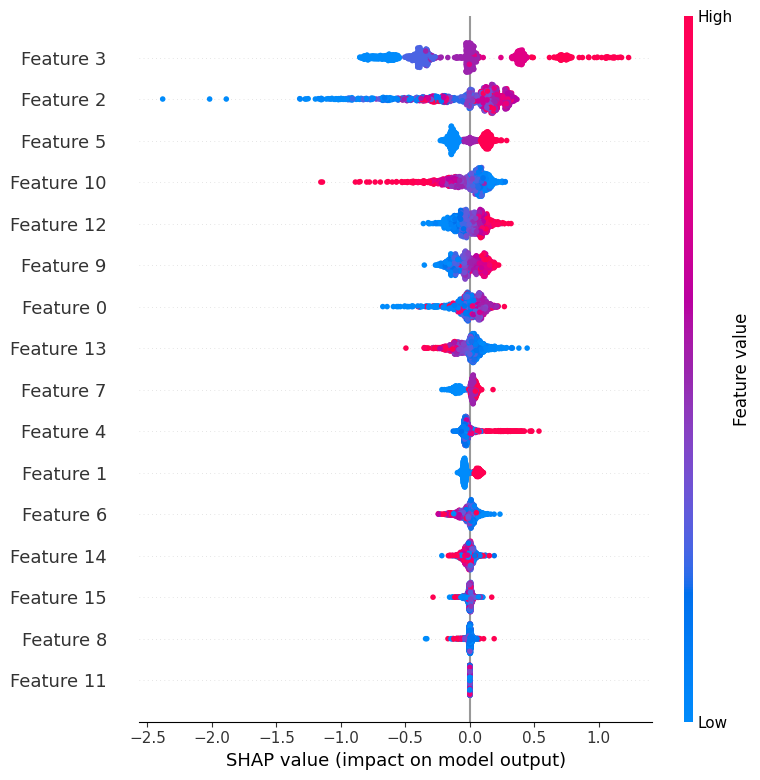

In [40]:
import shap

explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test[:1000])

shap.summary_plot(shap_values, X_test[:1000])

In [41]:
X.columns

Index(['loan_amnt', 'term', 'int_rate', 'grade', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti',
       'fico_range_low', 'fico_range_high', 'open_acc', 'revol_bal',
       'revol_util', 'total_acc'],
      dtype='str')

In [42]:
selected_columns

['loan_amnt',
 'term',
 'int_rate',
 'grade',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'purpose',
 'dti',
 'fico_range_low',
 'fico_range_high',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'risk_target']

In [43]:
encoders = joblib.load("../models/label_encoders.pkl")

for col, encoder in encoders.items():
    print(f"\n{col}")
    print(list(encoder.classes_))


term
[' 36 months', ' 60 months']

grade
['A', 'B', 'C', 'D', 'E', 'F', 'G']

emp_length
['1 year', '10+ years', '2 years', '3 years', '4 years', '5 years', '6 years', '7 years', '8 years', '9 years', '< 1 year', 'Unknown']

home_ownership
['ANY', 'MORTGAGE', 'OWN', 'RENT']

verification_status
['Not Verified', 'Source Verified', 'Verified']

purpose
['car', 'credit_card', 'debt_consolidation', 'educational', 'home_improvement', 'house', 'major_purchase', 'medical', 'moving', 'other', 'renewable_energy', 'small_business', 'vacation', 'wedding']


In [45]:
from sklearn.metrics import roc_auc_score

# Logistic Regression
lr_probs = model.predict_proba(X_test)[:, 1]
lr_roc = roc_auc_score(y_test, lr_probs)

# Random Forest
rf_probs = rf.predict_proba(X_test)[:, 1]
rf_roc = roc_auc_score(y_test, rf_probs)

print("Logistic Regression ROC-AUC:", lr_roc)
print("Random Forest ROC-AUC:", rf_roc)

Logistic Regression ROC-AUC: 0.7035028631631858
Random Forest ROC-AUC: 0.7030536639010694
